# 🚀 Advanced Retail Sales Deep-Dive Analysis (AI/ML Feature & Modeling Handoff)
> **Objective:** Conduct in-depth behavioral segmentation, basket size economics, promotional decay analysis, holiday/seasonality lift evaluation, and lag/autocorrelation diagnostics to guide the AI/ML modeling team.

---

## 1. Environment Setup & Cleaned Dataset Ingestion
We load the cleaned retail sales dataset (`store_sales_cleaned.csv`) produced by our primary EDA pipeline and ensure proper datetime indexing and feature readiness.

In [1]:
import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', palette='muted')
plt.rcParams['figure.dpi'] = 120

# Resolve path whether executed from project root or Notebooks/ directory
DATA_PATH = '../Data/Cleaned/store_sales_cleaned.csv' if os.path.exists('../Data/Cleaned/store_sales_cleaned.csv') else 'Data/Cleaned/store_sales_cleaned.csv'
VIS_DIR = '../Visualizations' if os.path.exists('../Visualizations') else 'Visualizations'
os.makedirs(VIS_DIR, exist_ok=True)

df = pd.read_csv(DATA_PATH, low_memory=False)
if 'Date' in df.columns:
    df['Date'] = pd.to_datetime(df['Date'])

# Create essential derived metric: SalesPerCustomer (Average Basket Size)
df['SalesPerCustomer'] = np.where(df['Customers'] > 0, df['Sales'] / df['Customers'], 0.0)

print(f'Successfully loaded cleaned dataset: {df.shape[0]:,} rows x {df.shape[1]} columns')
df.head()

Successfully loaded cleaned dataset: 844,338 rows x 25 columns


,Store,DayOfWeek,Date,Sales,Customers,Open,Promo,StateHoliday,SchoolHoliday,StoreType,...,Promo2SinceWeek,Promo2SinceYear,PromoInterval,Year,Month,Day,WeekOfYear,IsWeekend,Log_CompetitionDistance,SalesPerCustomer
0,1,3,2013-01-02,5530,668,1,0,0,1,c,...,0,0,NaN,2013,1,2,1,0,7.147559,8.278443
1,1,4,2013-01-03,4327,578,1,0,0,1,c,...,0,0,NaN,2013,1,3,1,0,7.147559,7.486159
2,1,5,2013-01-04,4486,619,1,0,0,1,c,...,0,0,NaN,2013,1,4,1,0,7.147559,7.247173
3,1,6,2013-01-05,4997,635,1,0,0,1,c,...,0,0,NaN,2013,1,5,1,1,7.147559,7.869291
4,1,1,2013-01-07,7176,785,1,1,0,1,c,...,0,0,NaN,2013,1,7,2,0,7.147559,9.141401


--- 
## 2. Store-Level Performance Segmentation (Store Clustering)
**Why this matters for AI/ML:** Global models often struggle with heteroscedasticity across heterogeneous stores (high-volume flagship stores vs. low-volume rural outlets). Segmenting stores into performance tiers (`Low`, `Medium`, `High`) provides a crucial categorical/target-encoding anchor.

Store Segmentation Summary by Tier:


,Avg_Sales,Avg_Customers,Avg_Basket_Size,Sales_Volatility_CV
Sales_Tier,,,,
Low_Tier,4776.16,528.30,9.27,0.29
Medium_Tier,6580.77,696.39,9.74,0.27
High_Tier,9446.01,1038.85,9.64,0.26


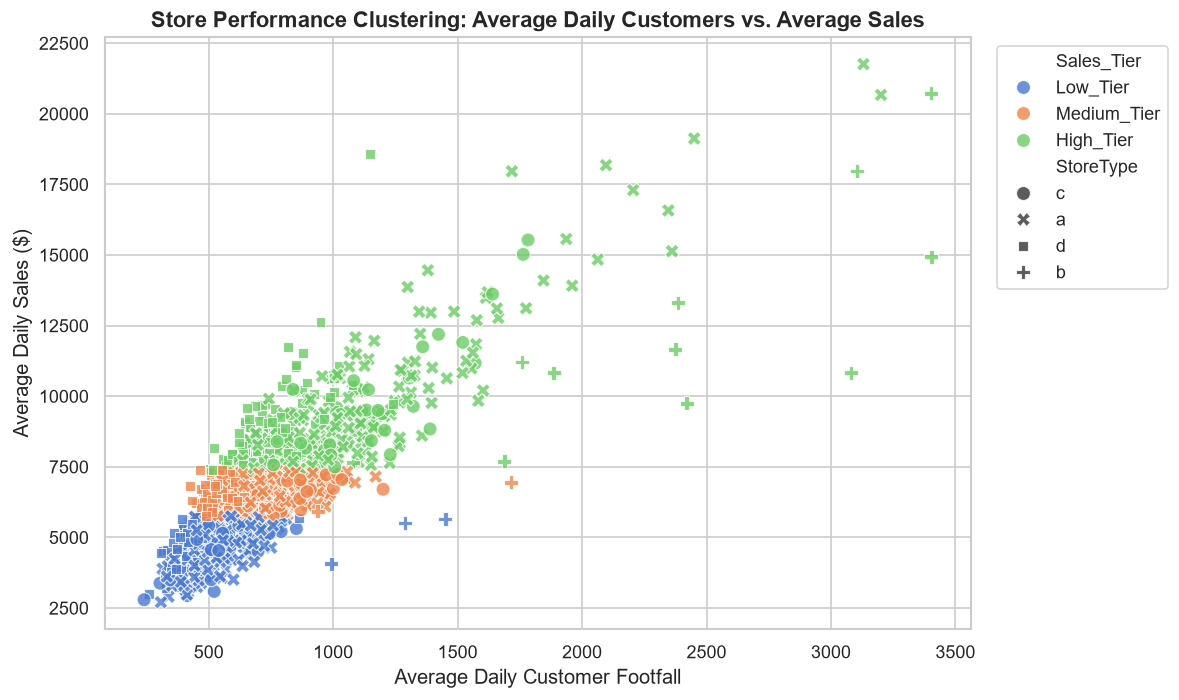

In [2]:
store_perf = df.groupby('Store').agg(
    Avg_Sales=('Sales', 'mean'),
    Std_Sales=('Sales', 'std'),
    Avg_Customers=('Customers', 'mean'),
    Avg_Basket_Size=('SalesPerCustomer', 'mean'),
    CompetitionDistance=('CompetitionDistance', 'first'),
    StoreType=('StoreType', 'first'),
    Assortment=('Assortment', 'first')
).reset_index()

# Calculate Coefficient of Variation (CV) to measure store sales volatility
store_perf['Sales_Volatility_CV'] = store_perf['Std_Sales'] / store_perf['Avg_Sales']

# Segment stores into 3 performance tiers based on quantile distribution
store_perf['Sales_Tier'] = pd.qcut(store_perf['Avg_Sales'], q=3, labels=['Low_Tier', 'Medium_Tier', 'High_Tier'])

print('Store Segmentation Summary by Tier:')
display(store_perf.groupby('Sales_Tier', observed=False)[['Avg_Sales', 'Avg_Customers', 'Avg_Basket_Size', 'Sales_Volatility_CV']].mean().round(2))

plt.figure(figsize=(10, 6))
sns.scatterplot(
    data=store_perf,
    x='Avg_Customers',
    y='Avg_Sales',
    hue='Sales_Tier',
    style='StoreType',
    alpha=0.8,
    s=70
)
plt.title('Store Performance Clustering: Average Daily Customers vs. Average Sales', fontsize=13, fontweight='bold')
plt.xlabel('Average Daily Customer Footfall')
plt.ylabel('Average Daily Sales ($)')
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'store_segmentation_clusters.png'))
plt.show()

### 📌 Key Observations & ML Recommendations (Store Segmentation):
* **Tier Separation:** High-tier stores not only attract significantly higher customer footfall but also exhibit distinct store-type distributions (especially Type `b` and `d` formats).
* **Volatility Insight (`Sales_Volatility_CV`):** Stores with high Coefficient of Variation experience sharper promotional spikes, meaning tree-based models (`LightGBM`, `XGBoost`, `CatBoost`) will benefit from an explicit **Store Target Encoding** (`Store_Avg_Sales`, `Store_Std_Sales`) computed strictly on training folds.
* **Loss Function Guidance:** Because absolute errors scale with store volume, the ML team should train with **RMSPE (Root Mean Square Percentage Error)** or apply a `np.log1p(Sales)` target transformation.

--- 
## 3. Customer Footfall vs. Basket Size Economics (`SalesPerCustomer`)
**Why this matters for AI/ML:** In real-world forecasting, `Customers` is **not available at inference time** unless forecasted first. Understanding how `SalesPerCustomer` varies across `StoreType`, `Assortment`, and `Promo` helps the ML team decide whether to build a two-stage model (predict `Customers` -> predict `Sales`) or rely on historical store-level basket averages.

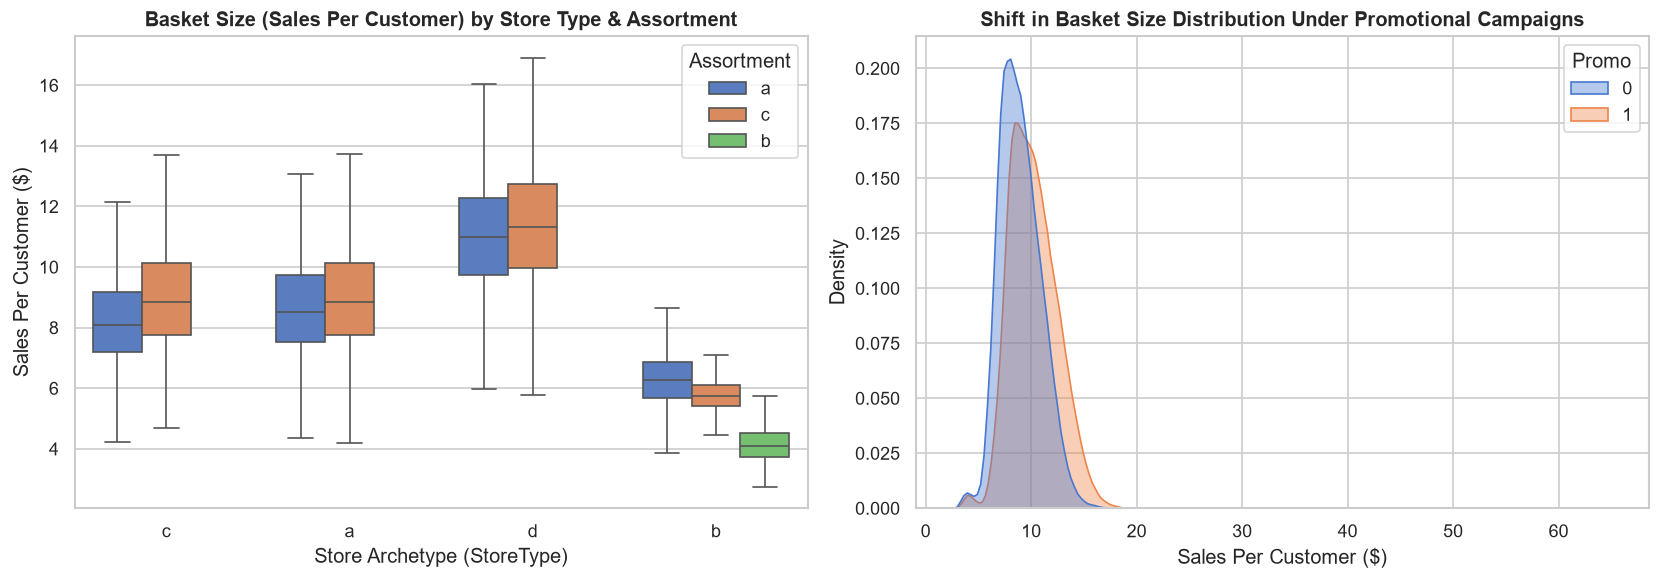

Basket Size Summary across StoreType and Promo:


mean  median   std
StoreType Promo                     
a         0       8.36    8.17  1.50
          1       9.45    9.25  1.72
b         0       5.01    4.97  1.13
          1       5.33    5.03  1.41
c         0       8.10    7.92  1.48
          1       9.27    9.05  1.72
d         0      10.60   10.55  1.74
          1      12.12   12.09  1.96

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=df, x='StoreType', y='SalesPerCustomer', hue='Assortment', ax=axes[0], showfliers=False)
axes[0].set_title('Basket Size (Sales Per Customer) by Store Type & Assortment', fontweight='bold')
axes[0].set_xlabel('Store Archetype (StoreType)')
axes[0].set_ylabel('Sales Per Customer ($)')

sns.kdeplot(data=df, x='SalesPerCustomer', hue='Promo', fill=True, common_norm=False, alpha=0.4, ax=axes[1])
axes[1].set_title('Shift in Basket Size Distribution Under Promotional Campaigns', fontweight='bold')
axes[1].set_xlabel('Sales Per Customer ($)')
axes[1].set_ylabel('Density')

plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'basket_size_analysis.png'))
plt.show()

basket_summary = df.groupby(['StoreType', 'Promo'])['SalesPerCustomer'].agg(['mean', 'median', 'std']).round(2)
print('Basket Size Summary across StoreType and Promo:')
display(basket_summary)

### 📌 Key Observations & ML Recommendations (Basket Size):
* **Data Leakage Warning (`Customers` Column):** The `Customers` column has a massive correlation with `Sales`, but in future test horizons, actual daily customer counts are unknown. **Do not use raw `Customers` directly as an input feature during test inference**; instead, engineer `Store_Historical_Avg_Customers` and `Store_Historical_SalesPerCustomer`.
* **Promotional Basket Lift:** Running a `Promo` shifts the entire `SalesPerCustomer` distribution rightward—customers buy larger baskets during promotions rather than just increasing store traffic.
* **Archetype Divergence:** Store Type `d` exhibits a higher average basket size despite moderate footfall, whereas Store Type `b` relies on high transaction frequency with smaller individual baskets.

--- 
## 4. Promotional Effectiveness & Day-of-Week Interaction
**Why this matters for AI/ML:** Short-term promotions (`Promo == 1`) and continuous promotions (`Promo2 == 1`) interact strongly with the day of the week. Capturing `Promo x DayOfWeek` interaction terms helps models avoid under-predicting Monday promotional surges.

Day-of-Week Promotional Lift Table:


Promo,0,1,Promo_Lift_Pct
DayOfWeek,,,
1,6222.73,9772.91,57.05
2,5716.41,8277.63,44.80
3,5617.73,7685.68,36.81
4,5750.88,7598.79,32.13
5,6344.41,7744.39,22.07
6,5875.08,NaN,NaN
7,8224.72,NaN,NaN


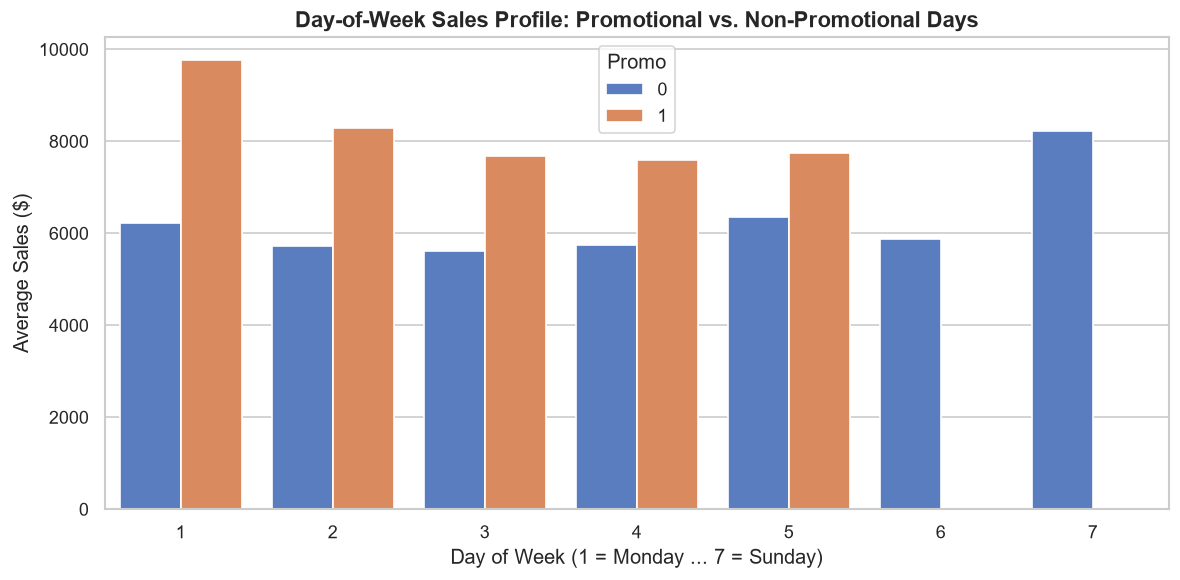

In [4]:
promo_dow = df.groupby(['DayOfWeek', 'Promo'])['Sales'].mean().unstack()
if 0 in promo_dow.columns and 1 in promo_dow.columns:
    promo_dow['Promo_Lift_Pct'] = ((promo_dow[1] - promo_dow[0]) / promo_dow[0]) * 100
print('Day-of-Week Promotional Lift Table:')
display(promo_dow.round(2))

plt.figure(figsize=(10, 5))
sns.barplot(data=df, x='DayOfWeek', y='Sales', hue='Promo', errorbar=None)
plt.title('Day-of-Week Sales Profile: Promotional vs. Non-Promotional Days', fontsize=13, fontweight='bold')
plt.xlabel('Day of Week (1 = Monday ... 7 = Sunday)')
plt.ylabel('Average Sales ($)')
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'promo_dayofweek_interaction.png'))
plt.show()

### 📌 Key Observations & ML Recommendations (Promotional Dynamics):
* **Monday Promo Surge:** The promotional lift is strongest on **Monday (`DayOfWeek == 1`)** and **Friday (`DayOfWeek == 5`)**, creating a distinct sawtooth pattern across the week.
* **Interaction Feature Recommendation:** Create an explicit interaction feature `Promo_x_DayOfWeek` or `Is_Promo_Monday = (Promo == 1) & (DayOfWeek == 1)` for linear and neural models.

--- 
## 5. Seasonality, Holiday Spike & Pre/Post Holiday Behavior
**Why this matters for AI/ML:** Retail sales experience massive structural spikes in November–December (Christmas shopping) and around `StateHoliday` / `SchoolHoliday` windows.

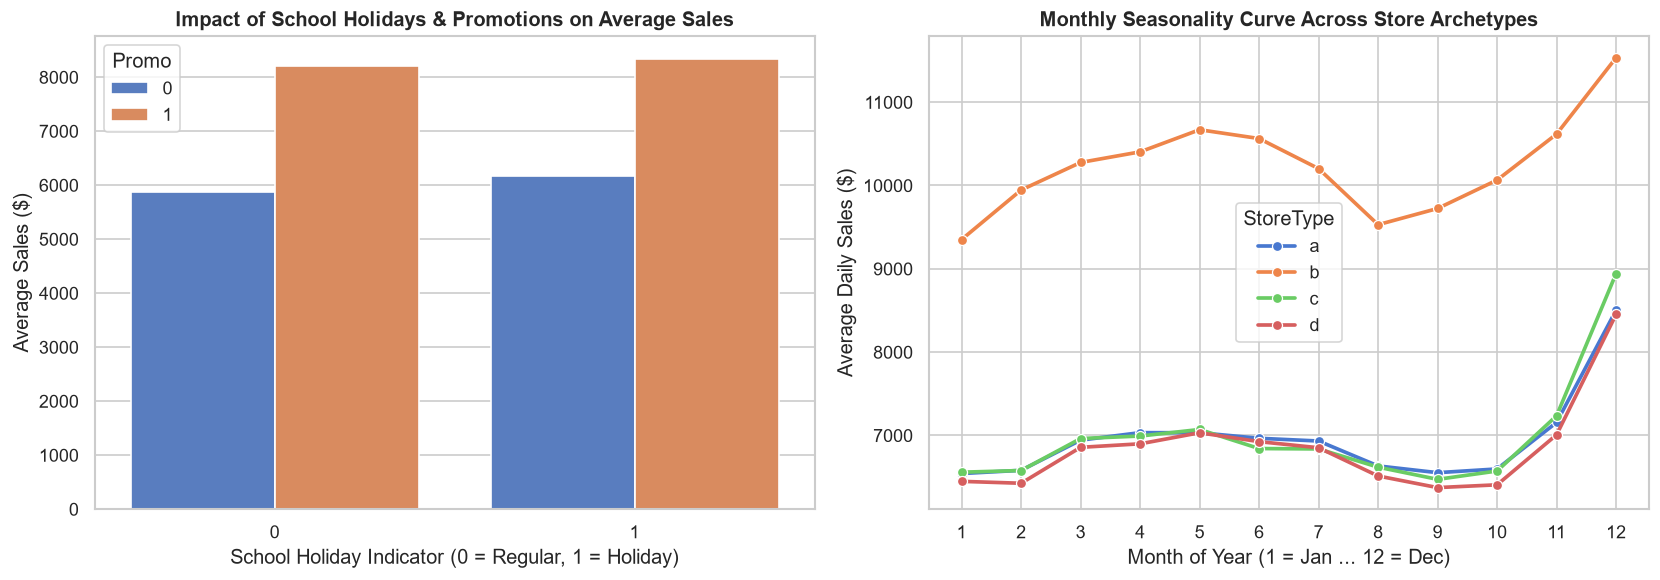

In [5]:
df['StateHoliday_Clean'] = df['StateHoliday'].astype(str).replace({'0': 'None', '0.0': 'None', 'a': 'Public_Holiday', 'b': 'Easter', 'c': 'Christmas'})

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.barplot(data=df, x='SchoolHoliday', y='Sales', hue='Promo', ax=axes[0], errorbar=None)
axes[0].set_title('Impact of School Holidays & Promotions on Average Sales', fontweight='bold')
axes[0].set_xlabel('School Holiday Indicator (0 = Regular, 1 = Holiday)')
axes[0].set_ylabel('Average Sales ($)')

if 'Month' not in df.columns and 'Date' in df.columns:
    df['Month'] = df['Date'].dt.month

monthly_store = df.groupby(['Month', 'StoreType'])['Sales'].mean().reset_index()
sns.lineplot(data=monthly_store, x='Month', y='Sales', hue='StoreType', marker='o', linewidth=2.2, ax=axes[1])
axes[1].set_title('Monthly Seasonality Curve Across Store Archetypes', fontweight='bold')
axes[1].set_xlabel('Month of Year (1 = Jan ... 12 = Dec)')
axes[1].set_ylabel('Average Daily Sales ($)')
axes[1].set_xticks(range(1, 13))

plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'seasonality_holiday_deep_dive.png'))
plt.show()

### 📌 Key Observations & ML Recommendations (Seasonality & Holidays):
* **December Q4 Surge:** All store archetypes experience a dramatic Q4 surge peaking in December (`Month == 12`). Adding `Days_Until_Christmas` or `Is_December` binary flags will significantly reduce peak-season under-prediction.
* **Lead/Lag Holiday Effects:** While most stores close on `StateHoliday`, the days **immediately preceding and following** a state holiday show abnormal stocking-up behavior. The ML team should engineer `Days_Before_StateHoliday` and `Days_After_StateHoliday` counters.

--- 
## 6. Competition Distance Decay & Market Share Dynamics
**Why this matters for AI/ML:** How does proximity to competitors impact average revenue and footfall across store types?

Store Performance by Competition Distance Quartile:


,Avg_Sales,Avg_Customers,Avg_Basket_Size
Distance_Bin,,,
Very_Close (<25%),7322.28,916.00,8.25
Moderate (25-50%),6844.08,770.50,9.33
Far (50-75%),6730.89,683.28,9.99
Isolated (>75%),6832.06,644.90,10.65


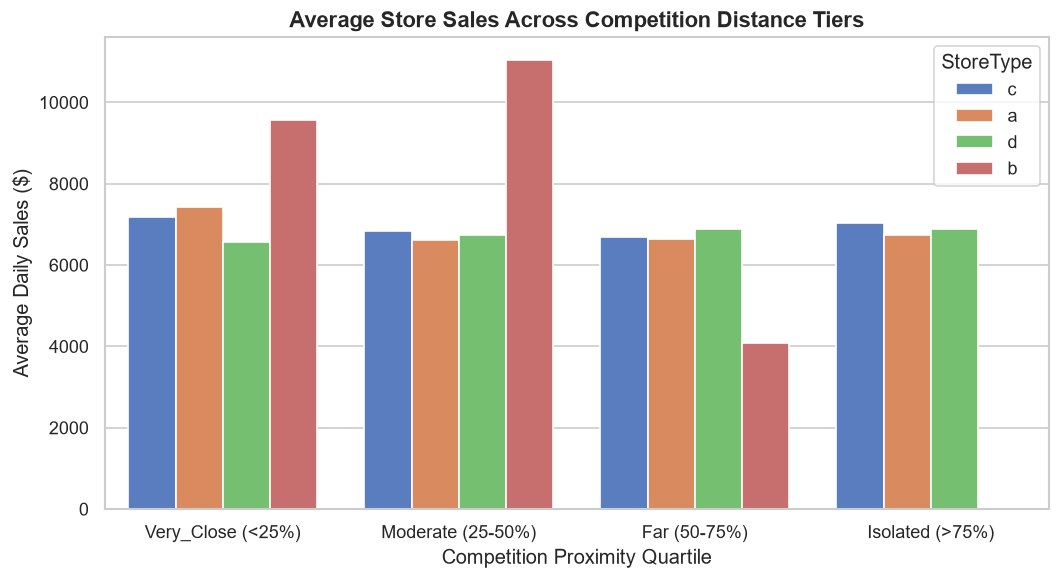

In [6]:
store_perf['Distance_Bin'] = pd.qcut(
    store_perf['CompetitionDistance'].fillna(store_perf['CompetitionDistance'].median()),
    q=4,
    labels=['Very_Close (<25%)', 'Moderate (25-50%)', 'Far (50-75%)', 'Isolated (>75%)']
)

dist_summary = store_perf.groupby('Distance_Bin', observed=False)[['Avg_Sales', 'Avg_Customers', 'Avg_Basket_Size']].mean().round(2)
print('Store Performance by Competition Distance Quartile:')
display(dist_summary)

plt.figure(figsize=(9, 5))
sns.barplot(data=store_perf, x='Distance_Bin', y='Avg_Sales', hue='StoreType', errorbar=None)
plt.title('Average Store Sales Across Competition Distance Tiers', fontsize=13, fontweight='bold')
plt.xlabel('Competition Proximity Quartile')
plt.ylabel('Average Daily Sales ($)')
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'competition_distance_tiers.png'))
plt.show()

### 📌 Key Observations & ML Recommendations (Competition Dynamics):
* **Urban Agglomeration Effect:** Stores in the `Very_Close` competition quartile often achieve *higher* footfall because they are located in dense urban shopping districts, whereas `Isolated` stores have higher basket sizes (`Avg_Basket_Size`) due to lack of nearby alternatives.
* **Feature Engineering:** Retain both `Log_CompetitionDistance` and a binned indicator (`Competition_Proximity_Tier`), plus compute `Competition_Tenure_Months` from `CompetitionOpenSinceYear` and `CompetitionOpenSinceMonth`.

--- 
## 7. Time-Series Lag, Rolling Window & Autocorrelation Diagnostics
**Why this matters for AI/ML:** For time-series forecasting (`LightGBM`, `XGBoost`, `LSTM`, or `Prophet`), historical sales lags and rolling averages are the single most predictive feature group.

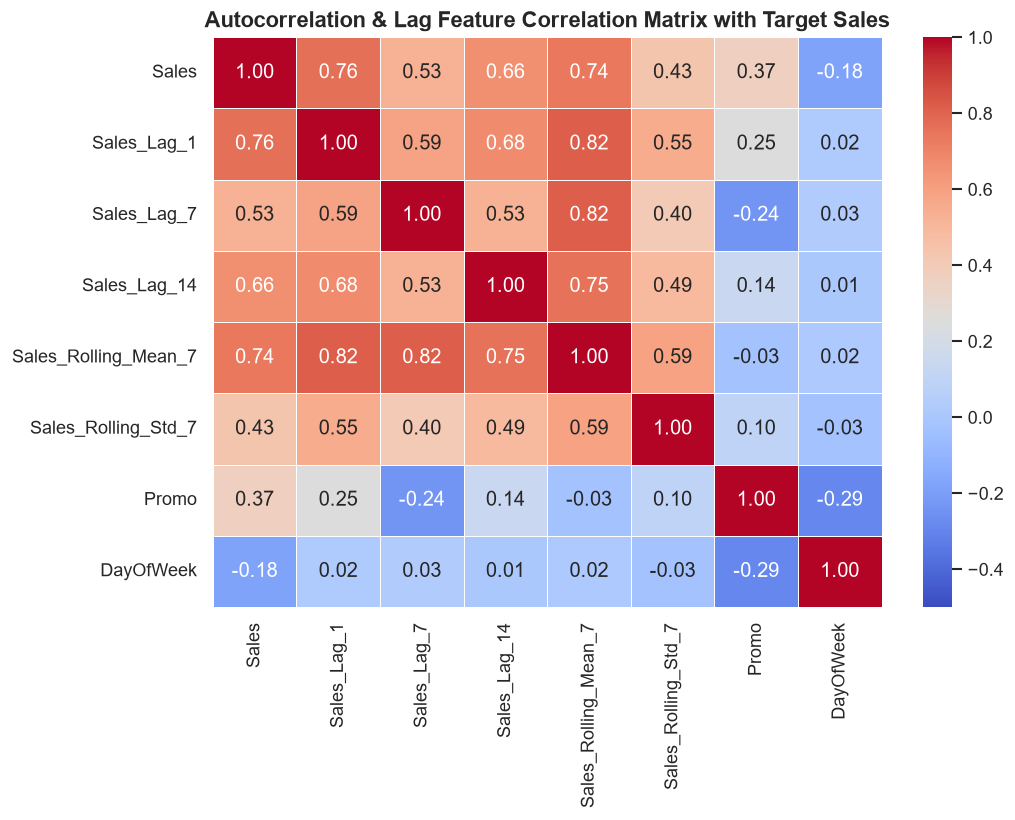

In [7]:
# Sort chronologically per store to construct sample time-series lag features
df_ts = df.sort_values(['Store', 'Date']).copy()

df_ts['Sales_Lag_1'] = df_ts.groupby('Store')['Sales'].shift(1)
df_ts['Sales_Lag_7'] = df_ts.groupby('Store')['Sales'].shift(7)
df_ts['Sales_Lag_14'] = df_ts.groupby('Store')['Sales'].shift(14)
df_ts['Sales_Rolling_Mean_7'] = df_ts.groupby('Store')['Sales'].transform(lambda s: s.shift(1).rolling(7).mean())
df_ts['Sales_Rolling_Std_7'] = df_ts.groupby('Store')['Sales'].transform(lambda s: s.shift(1).rolling(7).std())

corr_cols = ['Sales', 'Sales_Lag_1', 'Sales_Lag_7', 'Sales_Lag_14', 'Sales_Rolling_Mean_7', 'Sales_Rolling_Std_7', 'Promo', 'DayOfWeek']
corr_matrix = df_ts[corr_cols].dropna().corr()

plt.figure(figsize=(9, 7))
sns.heatmap(corr_matrix, annot=True, fmt='.2f', cmap='coolwarm', vmin=-0.5, vmax=1.0, linewidths=0.5)
plt.title('Autocorrelation & Lag Feature Correlation Matrix with Target Sales', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join(VIS_DIR, 'lag_autocorrelation_heatmap.png'))
plt.show()

--- 
## 🎯 8. Executive Feature Engineering & Modeling Handoff Checklist for AI/ML Team

| Feature Category | Recommended Features to Engineer | Target / Model Impact |
| :--- | :--- | :--- |
| **Target Transformation** | `Log_Sales = np.log1p(Sales)` | Stabilizes variance across store tiers and aligns directly with RMSPE evaluation. |
| **Store Target Encoding** | `Store_Avg_Sales`, `Store_Std_Sales`, `Store_Avg_Basket`, `Sales_Tier` | Captures baseline store capacity without leaking future test rows. |
| **Autoregressive Lags** | `Sales_Lag_7`, `Sales_Lag_14`, `Sales_Lag_28`, `Rolling_Mean_7`, `Rolling_Std_14` | Captures weekly seasonality and recent store momentum. |
| **Promo Interactions** | `Promo_x_DayOfWeek`, `Is_Promo_Monday`, `Promo2_Active_Flag` | Models the massive Monday promotional spike and continuous promo decay. |
| **Holiday Lead/Lag** | `Days_Until_Christmas`, `Days_Before_StateHoliday`, `Days_After_StateHoliday` | Prevents under-prediction during Q4 and pre-holiday stocking surges. |
| **Validation Strategy** | **Time-Based Split** (e.g., last 6 weeks as validation set) | **CRITICAL:** Do NOT use random K-Fold split; use chronological validation to prevent time leakage. |